# 11 · Uncertainty, Calibration and Robustness

This is a module of Neural Networks 1002. It assumes [module 03 of Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/03-training-deep-networks/) (training deep networks well: losses, regularisation, overfitting), [module 05](https://neural-networks.academy.forwardforecasting.eu/05-convolutional-networks/) (convolutional networks and image data) and [module 12](https://neural-networks.academy.forwardforecasting.eu/12-capstone-real-case/) (the capstone, where a model has to be trusted in a realistic setting).

A network that says "this is a 7" is useful. A network that says "this is a 7, and I would be right 55 % of the time when I sound this sure" is far more useful, because a person or a downstream system can decide what to do with it: accept, double-check, or hand over to an expert. This module is about producing, checking and protecting that second kind of statement.

In this notebook you will build and measure, on a laptop CPU with fixed seeds:

1. the two kinds of uncertainty, **aleatoric** (noise in the data) and **epistemic** (ignorance of the model), made visible on a one-dimensional regression toy;
2. **calibration**: reliability diagrams, the **expected calibration error** (ECE), why modern networks are overconfident, and **temperature scaling**;
3. three ways to get uncertainty out of a network, **deep ensembles**, **Monte Carlo dropout** and a **last-layer Laplace approximation**, compared on accuracy, calibration and **out-of-distribution** (OOD) detection (AUROC, area under the ROC curve);
4. **selective prediction**: let the model abstain and trade coverage for accuracy;
5. **conformal prediction**: prediction sets and intervals with a coverage guarantee that we measure, and watch break under distribution shift;
6. **quantile regression** and conformalised quantile regression for prediction intervals;
7. **distribution shift** with corrupted images (noise, blur, rotation);
8. **adversarial examples**: FGSM (fast gradient sign method) and PGD (projected gradient descent) implemented from scratch, an accuracy-versus-epsilon curve, and adversarial training with its cost;
9. **data augmentation** as a robustness tool, including what it does not buy you;
10. a **checklist** for putting a confidence in production.

**Contents**

1. Why a prediction needs a confidence
2. Aleatoric and epistemic uncertainty on a toy
3. Calibration and temperature scaling
4. Ensembles, MC dropout and a Laplace approximation
5. Selective prediction: accuracy versus coverage
6. Conformal prediction
7. Quantile regression and prediction intervals
8. Distribution shift: corrupted images
9. Adversarial examples and adversarial training
10. Data augmentation as a robustness tool
11. A checklist for production
12. Key takeaways, exercises, references

| Builds on | What we reuse |
|---|---|
| [03 Training deep networks (1001)](https://neural-networks.academy.forwardforecasting.eu/03-training-deep-networks/) | cross-entropy loss, Adam, overfitting and why a network can memorise noisy labels |
| [05 Convolutional networks (1001)](https://neural-networks.academy.forwardforecasting.eu/05-convolutional-networks/) | images as arrays of pixels, what a small shift of the input does |
| [12 Capstone (1001)](https://neural-networks.academy.forwardforecasting.eu/12-capstone-real-case/) | judging a model on data that differs from the training data |
| [07 Time series with neural networks (1001)](https://neural-networks.academy.forwardforecasting.eu/07-time-series-forecasting/) | forecasts with intervals, the idea behind section 7 |

New to PyTorch? The [Python 1001 course, section on AI frameworks](https://python.academy.forwardforecasting.eu/11-ai-frameworks/) introduces it, and its [time series section](https://python.academy.forwardforecasting.eu/12-time-series-forecasting/) covers prediction intervals for forecasts.

**Data and where the toys differ from real systems.** We use the 8 by 8 pixel handwritten digits that ship with scikit-learn (1797 images, the UCI "Optical Recognition of Handwritten Digits" test set by Alpaydin and Kaynak, CC BY 4.0 licence, [doi:10.24432/C50P49](https://doi.org/10.24432/C50P49)), so nothing is downloaded, plus a regression toy generated in the notebook. Real systems have far larger images, far richer shifts than our Gaussian noise or rotation, and datasets with millions of examples; the *methods* and the *measurements* carry over, the exact numbers do not. The whole notebook runs in a few minutes on a CPU.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks-1002/11_uncertainty_calibration_and_robustness.ipynb)

**Running in Google Colab?** Choose *Runtime > Run all*. The first code cell installs only what is missing (no session restart needed). **Measured run time** in a clean 2-CPU environment like Colab's: under a minute, with a peak memory of under 1 GB (model and data downloads were done on a fast connection). A free Colab CPU is usually slower than the machine used for the measurement, so allow more time; the timings printed in the saved outputs come from a multi-core machine.

In [ ]:
# Setup: works locally and in Google Colab. Installs only the packages that are missing.
import importlib.util, os, subprocess, sys

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'scipy': 'scipy',
    'sklearn': 'scikit-learn',
    'torch': 'torch',
}  # import name -> pip requirement
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Installing:', ', '.join(_missing))
    _r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], capture_output=True, text=True)
    if _r.returncode:
        print('WARNING: the pip install failed; continuing. Details:\n' + _r.stderr[-400:])
print(f"Environment: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()}")

In [1]:
import warnings
warnings.filterwarnings("ignore")
import time, math
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy import ndimage
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

torch.set_num_threads(2)
torch.manual_seed(0); np.random.seed(0)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
T_START = time.time()

digits = load_digits()
X_ALL = (digits.data / 16.0).astype(np.float32)      # pixel values scaled to [0, 1]
Y_ALL = digits.target
print("digits:", X_ALL.shape, "classes:", np.unique(Y_ALL))

digits: (1797, 64) classes: [0 1 2 3 4 5 6 7 8 9]


## 1. Why a prediction needs a confidence

A classifier's last layer produces numbers called **logits** (one per class). The **softmax** turns them into probabilities that sum to one, and we normally report the largest one as "the confidence" and its class as "the prediction". Two questions follow, and they are different:

* **Is the model right?** That is accuracy.
* **Does its confidence mean something?** If we collect all the predictions where the model said "90 %", is it right about 90 % of the time? That is **calibration**.

A model can be accurate and badly calibrated, or modest in accuracy and perfectly calibrated. A calibrated confidence lets you set a threshold ("send everything under 80 % to a person"), combine models, and price risk. And a confidence is only as good as the situation it was measured in: the **same** network, shown inputs unlike its training data, usually keeps sounding sure while its accuracy collapses. Most of this module is about that gap and about tools that narrow it. Words used throughout:

| Term | Meaning |
|---|---|
| **aleatoric uncertainty** | irreducible randomness in the data itself (a blurry photo, a noisy sensor). More data does not remove it |
| **epistemic uncertainty** | the model's lack of knowledge (too little data in a region, or inputs far from the training data). More data in that region does reduce it |
| **calibration** | agreement between stated confidence and observed frequency of being right |
| **in-distribution** (ID), **out-of-distribution** (OOD) | inputs like, or unlike, the training data |
| **distribution shift** | the data seen in use differs from the data seen in training |
| **coverage** | the fraction of cases where a prediction set or interval contains the truth |

## 2. Aleatoric and epistemic uncertainty on a toy

Take one input $x$ and one output $y$ with $y = f(x) + \sigma(x)\,\varepsilon$, where $f(x) = \sin(2.5x)$ is the true curve, $\varepsilon$ is standard normal noise, and the noise level $\sigma(x) = 0.05 + 0.1\,(x + 2)$ **grows with $x$** (written as a function of $x$ because the noise is not the same everywhere, which is called *heteroscedastic*). We train only on $x \in [-2, -0.6] \cup [0.6, 2]$, so there is a **gap** in the middle and nothing outside $[-2, 2]$.

Two different things are now unknown:

* In the data regions the curve is well known but each observation is noisy, more so on the right. That is **aleatoric** uncertainty: even with infinite data, $y$ at $x = 1.8$ stays random with standard deviation about $0.43$.
* In the gap and outside $[-2, 2]$ we have seen no data, so many curves fit equally well. That is **epistemic** uncertainty: different plausible models disagree.

To separate them we use a small **ensemble** of $M = 5$ networks. Each outputs a mean $\mu_m(x)$ and a variance $v_m(x)$ and is trained with the **Gaussian negative log-likelihood** (NLL), $\tfrac12\left[\ln v + (y-\mu)^2 / v\right]$, so it learns both the curve and its own noise level. The decomposition (Kendall and Gal, 2017) is then

$$\underbrace{\sigma_\text{ale}^2(x) = \frac1M \sum_m v_m(x)}_{\text{average predicted noise}}, \qquad \underbrace{\sigma_\text{epi}^2(x) = \frac1M \sum_m \big(\mu_m(x) - \bar\mu(x)\big)^2}_{\text{disagreement between members}}, \qquad \sigma_\text{tot}^2 = \sigma_\text{ale}^2 + \sigma_\text{epi}^2,$$

where $\bar\mu = \frac1M\sum_m \mu_m$ is the ensemble mean (the law of total variance).

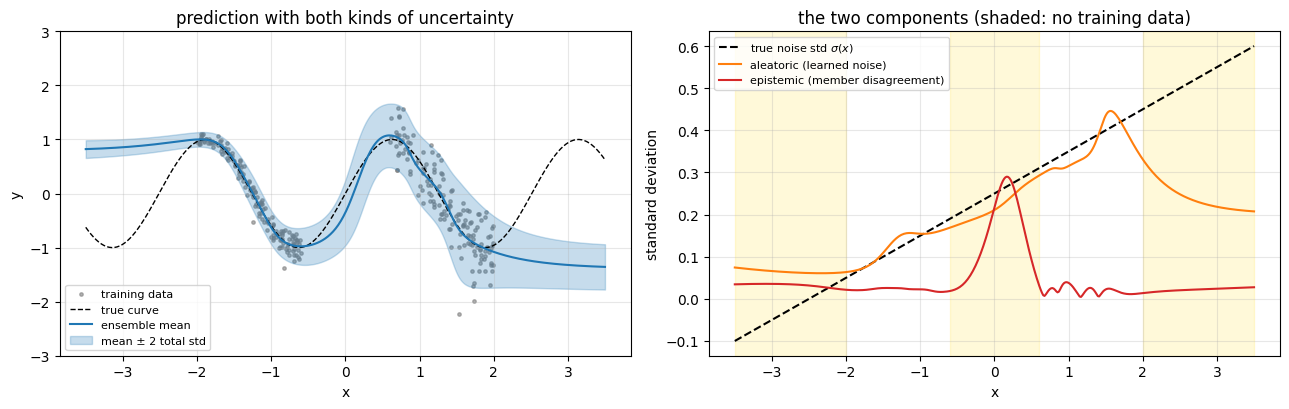

region                       true noise  aleatoric  epistemic
data region (0.6<|x|<2)           0.250      0.241      0.020
gap (|x|<0.5)                     0.250      0.219      0.162
extrapolation (|x|>2.5)           0.250      0.144      0.029
correlation of learned noise with true noise in the data region: 0.979
time 98 s


In [2]:
def f_true(x): return np.sin(2.5 * x)
def s_true(x): return 0.05 + 0.1 * (x + 2.0)

rng = np.random.default_rng(0)
x_tr = np.concatenate([rng.uniform(-2, -0.6, 150), rng.uniform(0.6, 2, 150)])
y_tr = f_true(x_tr) + s_true(x_tr) * rng.standard_normal(x_tr.size)
xt = torch.tensor(x_tr, dtype=torch.float32)[:, None]
yt = torch.tensor(y_tr, dtype=torch.float32)[:, None]

def fit_gauss(seed, steps=1000):
    torch.manual_seed(seed)
    net = nn.Sequential(nn.Linear(1, 64), nn.Tanh(), nn.Linear(64, 64), nn.Tanh(), nn.Linear(64, 2))
    opt = torch.optim.Adam(net.parameters(), lr=5e-3)
    for _ in range(steps):
        out = net(xt); mu, lv = out[:, :1], out[:, 1:].clamp(-9, 3)
        loss = (0.5 * (lv + (yt - mu) ** 2 / lv.exp())).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    return net

t0 = time.time()
members = [fit_gauss(s) for s in range(5)]
xg = np.linspace(-3.5, 3.5, 400)
with torch.no_grad():
    outs = torch.stack([m(torch.tensor(xg, dtype=torch.float32)[:, None]) for m in members])   # (M, N, 2)
mus = outs[:, :, 0].numpy()
vs = outs[:, :, 1].clamp(-9, 3).exp().numpy()
mu_bar = mus.mean(0)
sig_ale = np.sqrt(vs.mean(0))
sig_epi = mus.std(0)
sig_tot = np.sqrt(sig_ale ** 2 + sig_epi ** 2)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].scatter(x_tr, y_tr, s=6, c="gray", alpha=0.6, label="training data")
ax[0].plot(xg, f_true(xg), "k--", lw=1, label="true curve")
ax[0].plot(xg, mu_bar, c="C0", label="ensemble mean")
ax[0].fill_between(xg, mu_bar - 2 * sig_tot, mu_bar + 2 * sig_tot, color="C0", alpha=0.25, label="mean ± 2 total std")
ax[0].set_ylim(-3, 3); ax[0].set_xlabel("x"); ax[0].set_ylabel("y"); ax[0].legend(loc="lower left", fontsize=8)
ax[0].set_title("prediction with both kinds of uncertainty")
ax[1].plot(xg, s_true(xg), "k--", label="true noise std $\\sigma(x)$")
ax[1].plot(xg, sig_ale, c="C1", label="aleatoric (learned noise)")
ax[1].plot(xg, sig_epi, c="C3", label="epistemic (member disagreement)")
ax[1].axvspan(-0.6, 0.6, color="gold", alpha=0.15); ax[1].axvspan(-3.5, -2, color="gold", alpha=0.15); ax[1].axvspan(2, 3.5, color="gold", alpha=0.15)
ax[1].set_xlabel("x"); ax[1].set_ylabel("standard deviation"); ax[1].legend(fontsize=8); ax[1].set_title("the two components (shaded: no training data)")
plt.tight_layout(); plt.show()

reg = {"data region (0.6<|x|<2)": (np.abs(xg) > 0.6) & (np.abs(xg) < 2),
       "gap (|x|<0.5)": np.abs(xg) < 0.5,
       "extrapolation (|x|>2.5)": np.abs(xg) > 2.5}
print(f"{'region':28s} {'true noise':>10s} {'aleatoric':>10s} {'epistemic':>10s}")
for k, m in reg.items():
    print(f"{k:28s} {s_true(xg[m]).mean():10.3f} {sig_ale[m].mean():10.3f} {sig_epi[m].mean():10.3f}")
d = reg["data region (0.6<|x|<2)"]
print("correlation of learned noise with true noise in the data region:", round(float(np.corrcoef(sig_ale[d], s_true(xg[d]))[0, 1]), 3))
print(f"time {time.time() - t0:.0f} s")

**Reading.** The learned noise level follows the true one in the data region (correlation 0.98 with $\sigma(x)$, average 0.24 against a true 0.25), so the aleatoric part is learned well where there is data. The epistemic part is small in the data region (0.020) and **eight times larger in the gap** (0.162), as it should be: the members agree where they have seen data and disagree where they have not. Honestly, the extrapolation outside $[-2, 2]$ is a **weak spot**: the epistemic standard deviation there is only 0.029, because these tanh networks all flatten out in a similar way, so five members agree on a wrong continuation, and the learned noise (0.144) falls below the true noise there. Disagreement between members underestimates ignorance when the members share the same inductive bias. One seed set; the numbers move a little with the seeds.

**Where the toy differs from real systems.** Real networks have millions of weights, so a handful of ensemble members only samples the space of plausible models very sparsely; and real noise is rarely Gaussian. The separation also depends on the model being able to represent the noise: a network trained with plain squared error has no aleatoric output at all.

## 3. Calibration and temperature scaling

For a classifier with predicted class $\hat y$ and confidence $\hat p = \max_k p_k$ (the largest softmax probability), the model is **perfectly calibrated** when $P(\hat y = y \mid \hat p = c) = c$ for every confidence level $c$. We estimate this by sorting predictions into $B$ equal-width confidence bins $b$ and comparing, per bin, the **accuracy** $\mathrm{acc}(b)$ with the mean **confidence** $\mathrm{conf}(b)$. A **reliability diagram** plots $\mathrm{acc}(b)$ against $\mathrm{conf}(b)$ (the diagonal is perfect), and the **expected calibration error** summarises it,

$$\mathrm{ECE} = \sum_{b=1}^{B} \frac{n_b}{n}\,\big|\mathrm{acc}(b) - \mathrm{conf}(b)\big|,$$

where $n_b$ is the number of predictions in bin $b$ and $n$ the total (we use $B = 15$). We also report the **NLL** (the average of $-\ln p_{\text{true class}}$), a proper score that rewards both accuracy and honest probabilities.

**Why modern networks are overconfident.** Guo et al. (2017) showed that deep networks trained to near zero training loss become overconfident: cross-entropy keeps rewarding larger logits long after every training example is classified correctly, so the probabilities are pushed towards 0 and 1 regardless of how reliable they are on new data. To make this visible in a small problem we train a network on only 500 digits, **25 % of which have a wrong label** (a realistic situation: labelling is never perfect), for long enough to memorise them. The test set is clean.

**Temperature scaling** is the simplest fix. Divide the logits $z$ by one number $T > 0$ before the softmax, $p = \mathrm{softmax}(z / T)$, and choose $T$ by minimising the NLL on a held-out validation set. $T > 1$ softens the probabilities. The ranking of the classes does not change, so **accuracy is untouched**; only the confidence is.

labels actually changed: 98 of 500


fitted temperature T = 2.51
                    accuracy     NLL     ECE  mean conf
raw                    0.782   1.148   0.138      0.920
temperature-scaled     0.782   0.720   0.029      0.770


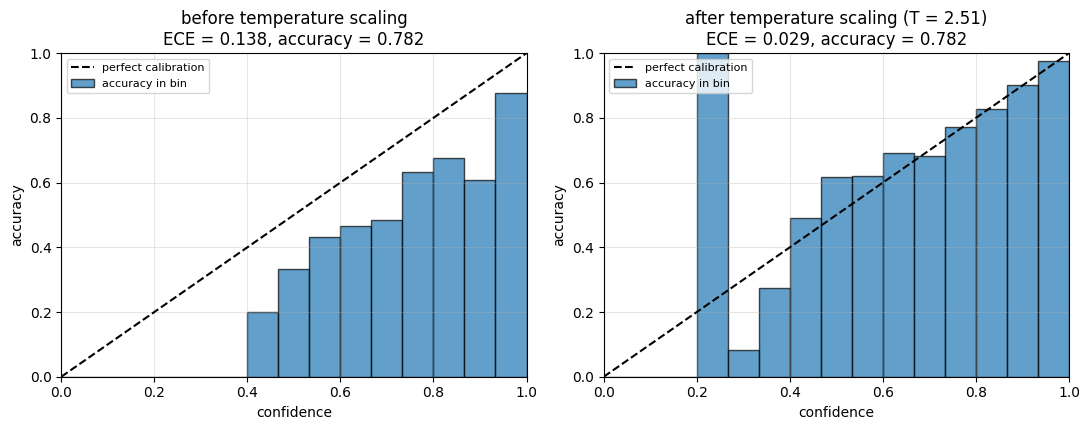

time 5 s


In [3]:
def softmax_np(z):
    z = z - z.max(-1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(-1, keepdims=True)

def ece_score(p, y, bins=15):
    conf = p.max(1); correct = p.argmax(1) == y
    edges = np.linspace(0, 1, bins + 1); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return e

def nll_score(p, y):
    return float(-np.log(p[np.arange(len(y)), y] + 1e-12).mean())

def make_mlp(d_out, p=0.0, h=128):
    return nn.Sequential(nn.Linear(64, h), nn.ReLU(), nn.Dropout(p), nn.Linear(h, h), nn.ReLU(), nn.Dropout(p), nn.Linear(h, d_out))

def fit(X, y, seed, d_out=10, epochs=100, lr=3e-3, p=0.0):
    # full-batch Adam on a small training set
    torch.manual_seed(seed)
    m = make_mlp(d_out, p); opt = torch.optim.Adam(m.parameters(), lr=lr)
    Xt = torch.as_tensor(X, dtype=torch.float32); yt_ = torch.as_tensor(y)
    m.train()
    for _ in range(epochs):
        loss = F.cross_entropy(m(Xt), yt_)
        opt.zero_grad(); loss.backward(); opt.step()
    return m.eval()

def logits_of(m, X):
    with torch.no_grad():
        return m(torch.as_tensor(X, dtype=torch.float32)).numpy()

def fit_temperature(z_val, y_val):
    logT = torch.zeros(1, requires_grad=True)
    zt, yv = torch.as_tensor(z_val), torch.as_tensor(y_val)
    opt = torch.optim.LBFGS([logT], lr=0.1, max_iter=100)
    def closure():
        opt.zero_grad(); l = F.cross_entropy(zt / logT.exp(), yv); l.backward(); return l
    opt.step(closure)
    return float(logT.exp())

def reliability(ax, p, y, title, bins=15):
    conf = p.max(1); correct = p.argmax(1) == y
    edges = np.linspace(0, 1, bins + 1); centres = (edges[:-1] + edges[1:]) / 2
    accs = np.full(bins, np.nan)
    cnt = np.zeros(bins)
    for i, (lo, hi) in enumerate(zip(edges[:-1], edges[1:])):
        m = (conf > lo) & (conf <= hi); cnt[i] = m.sum()
        if m.any(): accs[i] = correct[m].mean()
    ax.bar(centres, np.nan_to_num(accs), width=1 / bins, edgecolor="k", alpha=0.7, color="C0", label="accuracy in bin")
    ax.plot([0, 1], [0, 1], "k--", label="perfect calibration")
    ax.set_xlabel("confidence"); ax.set_ylabel("accuracy"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_title(f"{title}\nECE = {ece_score(p, y, bins):.3f}, accuracy = {correct.mean():.3f}"); ax.legend(loc="upper left", fontsize=8)

# 10-class split: 500 train (25 % wrong labels), 300 validation, the rest test
idx_tr, idx_rest = train_test_split(np.arange(len(Y_ALL)), train_size=500, stratify=Y_ALL, random_state=0)
idx_va, idx_te = train_test_split(idx_rest, train_size=300, stratify=Y_ALL[idx_rest], random_state=0)
Xtr, ytr_clean = X_ALL[idx_tr], Y_ALL[idx_tr]
Xva, yva, Xte, yte = X_ALL[idx_va], Y_ALL[idx_va], X_ALL[idx_te], Y_ALL[idx_te]
rng = np.random.default_rng(0)
ytr_noisy = ytr_clean.copy(); flip = rng.random(len(ytr_noisy)) < 0.25
ytr_noisy[flip] = rng.integers(0, 10, flip.sum())
print("labels actually changed:", int((ytr_noisy != ytr_clean).sum()), "of", len(ytr_noisy))

t0 = time.time()
net_noisy = fit(Xtr, ytr_noisy, seed=0, epochs=300)
z_va, z_te = logits_of(net_noisy, Xva), logits_of(net_noisy, Xte)
T = fit_temperature(z_va, yva)
p_raw, p_ts = softmax_np(z_te), softmax_np(z_te / T)
print(f"fitted temperature T = {T:.2f}")
print(f"{'':18s} {'accuracy':>9s} {'NLL':>7s} {'ECE':>7s} {'mean conf':>10s}")
for name, p in [("raw", p_raw), ("temperature-scaled", p_ts)]:
    print(f"{name:18s} {(p.argmax(1) == yte).mean():9.3f} {nll_score(p, yte):7.3f} {ece_score(p, yte):7.3f} {p.max(1).mean():10.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
reliability(ax[0], p_raw, yte, "before temperature scaling")
reliability(ax[1], p_ts, yte, f"after temperature scaling (T = {T:.2f})")
plt.tight_layout(); plt.show()
print(f"time {time.time() - t0:.0f} s")

**Reading.** The network is accurate only 78 % of the time, yet its average confidence is 92 %: **overconfident by 14 points** (ECE 0.138, NLL 1.15). One fitted temperature, $T = 2.51$, lowers the mean confidence to 77 %, close to the accuracy, ECE to 0.029 and NLL to 0.72, with **identical accuracy** (0.782). The reliability diagram moves onto the diagonal. Temperature scaling cannot make the model more accurate and it applies the same softening to every input; it only repairs the average.

**Where the toy differs from real systems.** The 25 % label noise is an exaggeration chosen so that overconfidence shows up on a tiny problem; large networks on large clean datasets are overconfident for subtler reasons (depth, width, weight decay and normalisation all change it, see Guo et al., 2017). One more caution: the validation set that fits $T$ is small here, and a $T$ fitted on clean data does **not** transfer to shifted data, which we measure in sections 6 and 8.

## 4. Ensembles, MC dropout and a Laplace approximation

Temperature scaling fixes the *average* confidence but gives every input the same treatment. We want uncertainty that is **larger for inputs the model has not learned**. Three practical ways, all in the family of approximating the **Bayesian predictive distribution** (average the predictions of many plausible networks instead of trusting one):

* **Deep ensemble** (Lakshminarayanan et al., 2017). Train $M$ networks from different random initialisations and average their softmax outputs. Simple and strong, but $M$ times the training and prediction cost. We use $M = 5$.
* **Monte Carlo (MC) dropout** (Gal and Ghahramani, 2016). Train with dropout (randomly zeroing units) and **keep dropout on at prediction time**: each of $S = 30$ stochastic forward passes is a different thinned network, and we average them. One training run, $S$ times the prediction cost.
* **Last-layer Laplace approximation** (see Daxberger et al., 2021). Keep one trained network, treat all layers but the last as a fixed feature extractor $\phi(x)$, and put a Gaussian distribution on the **last layer's weights** $W$ around their trained value $\hat W$ with covariance $\Sigma = \left(\sum_i \phi_i\phi_i^\top \otimes \mathrm{diag}(p_i) - p_ip_i^\top + \lambda I\right)^{-1}$ (the inverse of the loss curvature on the training set plus a prior precision $\lambda$; $\otimes$ is the Kronecker product). Sample weights, average the softmax. It is cheap (one matrix inverse) but only captures uncertainty in the last layer.

**The experiment.** To measure whether the uncertainty is useful we make a 7-class problem: train on digits 0 to 6 only. Then we test on three sets:

1. **in-distribution** test images (digits 0 to 6, clean);
2. **held-out classes**: images of digits 7, 8 and 9, which the model has never seen and cannot name correctly (a pure OOD case);
3. **shifted dataset**: the in-distribution test images corrupted with strong pixel noise (standard deviation 0.4, values clipped to $[0,1]$), the same classes but a different "sensor".

OOD detection is scored by **AUROC**: the probability that a random OOD input gets a higher "uncertainty score" than a random in-distribution one (1.0 perfect, 0.5 chance). The score is $1 - \hat p$ (one minus the largest averaged probability, the **maximum softmax probability**, MSP, baseline of Hendrycks and Gimpel, 2017). For ensembles and MC dropout we also try the **mutual information** $\mathrm{MI} = H(\bar p) - \tfrac1M\sum_m H(p_m)$, where $H$ is the entropy and $\bar p$ the average of the members' probabilities: it is large when the members *disagree*, that is the epistemic part. Everything is repeated for 3 random splits and initialisations, because on small test sets one run is noisy.

In [4]:
def entropy(p): return -(p * np.log(p + 1e-12)).sum(-1)

def laplace_sampler(net, Xtr_, prior_prec, n_samples=60, seed=0):
    # Gaussian over the last-layer weights (incl. bias), curvature from the training set
    with torch.no_grad():
        feats = net[:-1](torch.as_tensor(Xtr_, dtype=torch.float32))
        phi = torch.cat([feats, torch.ones(len(feats), 1)], 1)                 # (n, D)
        p = torch.softmax(net[-1](feats), 1)                                   # (n, K)
        W = torch.cat([net[-1].weight, net[-1].bias[:, None]], 1)              # (K, D)
        K, D = W.shape
        A = torch.diag_embed(p) - p[:, :, None] * p[:, None, :]                # (n, K, K)
        H = torch.einsum("ikl,ij,im->kjlm", A, phi, phi).reshape(K * D, K * D) + prior_prec * torch.eye(K * D)
        cov = torch.linalg.inv(H); cov = (cov + cov.T) / 2
        L = torch.linalg.cholesky(cov + 1e-7 * torch.eye(K * D))
        g = torch.Generator().manual_seed(seed)
        Ws = (W.reshape(-1)[:, None] + L @ torch.randn(K * D, n_samples, generator=g)).T.reshape(n_samples, K, D)
    def predict(X):
        with torch.no_grad():
            f = net[:-1](torch.as_tensor(X, dtype=torch.float32)); f = torch.cat([f, torch.ones(len(f), 1)], 1)
            return torch.softmax(torch.einsum("nd,skd->snk", f, Ws), -1).numpy()    # (S, n, K)
    return predict

def mc_dropout_predict(net, X, S=30, seed=0):
    torch.manual_seed(seed); net.train()
    with torch.no_grad():
        out = torch.stack([torch.softmax(net(torch.as_tensor(X, dtype=torch.float32)), -1) for _ in range(S)]).numpy()
    net.eval(); return out

def corrupt_noise(X, sigma, seed=0):
    r = np.random.default_rng(seed)
    return np.clip(X + sigma * r.standard_normal(X.shape), 0, 1).astype(np.float32)

METHODS = ["single", "single + temperature", "MC dropout", "deep ensemble (5)", "last-layer Laplace"]

def run_seed(seed):
    ins = Y_ALL < 7
    Xi, yi, Xo = X_ALL[ins], Y_ALL[ins], X_ALL[~ins]
    Xtr_, Xrest, ytr_, yrest = train_test_split(Xi, yi, train_size=400, stratify=yi, random_state=seed)
    Xva_, Xte_, yva_, yte_ = train_test_split(Xrest, yrest, train_size=0.4, stratify=yrest, random_state=seed)
    sets = {"id": Xte_, "ood": Xo, "shift": corrupt_noise(Xte_, 0.4, seed), "mix": corrupt_noise(Xte_, 0.25, seed + 100)}
    single = fit(Xtr_, ytr_, seed, d_out=7)
    Tm = fit_temperature(logits_of(single, Xva_), yva_)
    drop = fit(Xtr_, ytr_, seed, d_out=7, p=0.2)
    ens = [fit(Xtr_, ytr_, seed * 100 + k, d_out=7) for k in range(5)]
    # choose the Laplace prior precision on validation NLL
    best = None
    for lam in [1, 10, 100, 1000]:
        pr = laplace_sampler(single, Xtr_, lam, seed=seed)
        nll = nll_score(pr(Xva_).mean(0), yva_)
        if best is None or nll < best[0]: best = (nll, lam, pr)
    lap = best[2]
    pred = {}
    for name, X in sets.items():
        pred[name] = {
            "single": softmax_np(logits_of(single, X))[None],
            "single + temperature": softmax_np(logits_of(single, X) / Tm)[None],
            "MC dropout": mc_dropout_predict(drop, X, seed=seed),
            "deep ensemble (5)": np.stack([softmax_np(logits_of(m, X)) for m in ens]),
            "last-layer Laplace": lap(X),
        }
    return {"pred": pred, "y": yte_, "T": Tm, "lam": best[1]}

t0 = time.time()
runs = [run_seed(s) for s in range(3)]
print(f"trained {3 * 7} networks in {time.time() - t0:.0f} s; temperatures {[round(r['T'], 2) for r in runs]}; Laplace prior precisions {[r['lam'] for r in runs]}")

def mean_std(v): return f"{np.mean(v):.3f}±{np.std(v):.3f}"
cols = ["accuracy", "NLL", "ECE", "AUROC class MSP", "AUROC shift MSP", "AUROC class MI", "AUROC shift MI"]
print(f"{'method':22s} " + " ".join(f"{c:>15s}" for c in cols))
table = {}
for meth in METHODS:
    vals = {c: [] for c in cols}
    for r in runs:
        P = r["pred"]; y = r["y"]; pid = P["id"][meth].mean(0)
        vals["accuracy"].append((pid.argmax(1) == y).mean()); vals["NLL"].append(nll_score(pid, y)); vals["ECE"].append(ece_score(pid, y))
        for key, nm in [("ood", "class"), ("shift", "shift")]:
            po = P[key][meth].mean(0)
            s_id, s_o = 1 - pid.max(1), 1 - po.max(1)
            vals[f"AUROC {nm} MSP"].append(roc_auc_score(np.r_[np.zeros(len(s_id)), np.ones(len(s_o))], np.r_[s_id, s_o]))
            if P["id"][meth].shape[0] > 1:
                mi = lambda S: entropy(S.mean(0)) - entropy(S).mean(0)
                a, b = mi(P["id"][meth]), mi(P[key][meth])
                vals[f"AUROC {nm} MI"].append(roc_auc_score(np.r_[np.zeros(len(a)), np.ones(len(b))], np.r_[a, b]))
    table[meth] = vals
    print(f"{meth:22s} " + " ".join(f"{mean_std(vals[c]) if vals[c] else '-':>15s}" for c in cols))

trained 21 networks in 49 s; temperatures [1.64, 1.16, 1.51]; Laplace prior precisions [100, 1000, 100]
method                        accuracy             NLL             ECE AUROC class MSP AUROC shift MSP  AUROC class MI  AUROC shift MI
single                     0.977±0.009     0.090±0.026     0.015±0.004     0.940±0.012     0.796±0.012               -               -
single + temperature       0.977±0.009     0.079±0.018     0.009±0.002     0.944±0.011     0.798±0.012               -               -
MC dropout                 0.979±0.008     0.072±0.020     0.010±0.002     0.939±0.016     0.814±0.012     0.933±0.016     0.812±0.010


deep ensemble (5)          0.975±0.009     0.082±0.026     0.013±0.006     0.946±0.009     0.814±0.012     0.953±0.009     0.854±0.008
last-layer Laplace         0.978±0.009     0.084±0.021     0.011±0.001     0.939±0.010     0.796±0.012     0.934±0.009     0.794±0.014


**Reading.** On clean in-distribution digits all methods are accurate (97.5 to 97.9 %) and well calibrated (ECE about 0.01), because the clean problem is easy; **differences in accuracy, NLL and ECE between methods are within one standard deviation across seeds**, so we cannot rank them there (temperature scaling and MC dropout have the lowest NLL, 0.079 and 0.072, against 0.090 for the single network, a small gain). For detecting the **held-out classes** every method reaches AUROC 0.94 to 0.95 with the maximum probability, and the ensemble's mutual information is marginally the best (0.953), again inside the noise. The clearest difference is on the **shifted dataset**: with the maximum probability the ensemble and MC dropout reach 0.814 against 0.796 for the single network and Laplace, and the **ensemble's mutual information** gives 0.854 (spread 0.008), a gain larger than the seed noise. The last-layer Laplace approximation, which only models the last layer, did not help on any measure here. Shifted images are hard to flag for every method (AUROC at most 0.85).

**Where the toy differs from real systems.** Real OOD detection is much harder: unseen classes in natural images look *similar* to seen ones, and the shifts are semantic, not additive noise. Ovadia et al. (2019) benchmarked these same methods on large image, text and tabular datasets under shift and found the ensemble the most robust, with all methods degrading as the shift grows; our result agrees in direction but our numbers come from 8 by 8 digits and 3 seeds.

## 5. Selective prediction: accuracy versus coverage

Calibration and uncertainty become useful when they drive a decision. The simplest is the **reject option** (also called selective classification, Geifman and El-Yaniv, 2017): answer only when the confidence is above a threshold, and abstain otherwise (hand the case to a person). Two numbers describe each threshold:

* **coverage**: the fraction of inputs the model answers;
* **selective accuracy**: the accuracy on the answered ones.

Sweeping the threshold gives the **accuracy-versus-coverage** curve. A good confidence ranks errors below correct answers, so accuracy rises as coverage falls. The dashed **oracle** line is the best possible: it rejects exactly the wrong answers first. We rank by each method's maximum averaged probability and evaluate on a 50/50 mixture of clean test images and the same images with moderate noise (standard deviation 0.25), the kind of mixed traffic a deployed system sees. We also report the **AURC** (area under the risk-coverage curve, where risk is the error rate; lower is better) averaged over the three seeds.

method                  acc@100%   acc@80%   acc@50%  AURC (lower=better)
single                     0.955     0.992     0.998               0.0054
single + temperature       0.955     0.992     0.998               0.0054
MC dropout                 0.957     0.993     0.999               0.0042
deep ensemble (5)          0.952     0.995     0.999               0.0046
last-layer Laplace         0.956     0.991     0.998               0.0057


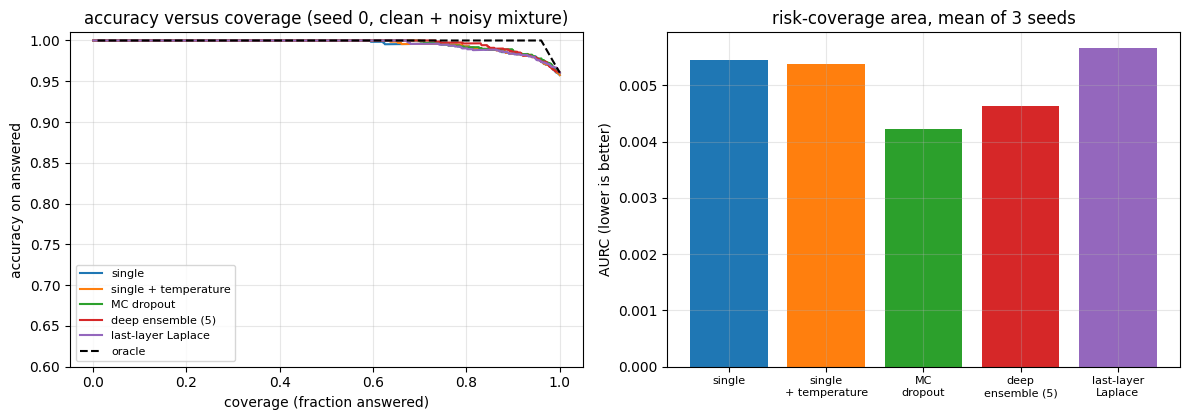

In [5]:
def sel_curve(p, y):
    order = np.argsort(-p.max(1)); correct = (p.argmax(1) == y)[order]
    cov = np.arange(1, len(y) + 1) / len(y)
    return cov, np.cumsum(correct) / np.arange(1, len(y) + 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
r0 = runs[0]; y_mix = np.r_[r0["y"], r0["y"]]
for k, meth in enumerate(METHODS):
    p = np.concatenate([r0["pred"]["id"][meth].mean(0), r0["pred"]["mix"][meth].mean(0)])
    cov, acc = sel_curve(p, y_mix); ax[0].plot(cov, acc, c=f"C{k}", label=meth)
base = (p.argmax(1) == y_mix).mean()
cov = np.linspace(0.01, 1, 200); ax[0].plot(cov, np.minimum(1, base / cov), "k--", label="oracle")
ax[0].set_xlabel("coverage (fraction answered)"); ax[0].set_ylabel("accuracy on answered"); ax[0].set_title("accuracy versus coverage (seed 0, clean + noisy mixture)")
ax[0].set_ylim(0.6, 1.01); ax[0].legend(fontsize=8, loc="lower left")

print(f"{'method':22s} {'acc@100%':>9s} {'acc@80%':>9s} {'acc@50%':>9s} {'AURC (lower=better)':>20s}")
res = {}
for meth in METHODS:
    a100, a80, a50, aurc = [], [], [], []
    for r in runs:
        yy = np.r_[r["y"], r["y"]]
        p = np.concatenate([r["pred"]["id"][meth].mean(0), r["pred"]["mix"][meth].mean(0)])
        cov, acc = sel_curve(p, yy)
        a100.append(acc[-1]); a80.append(acc[int(0.8 * len(acc)) - 1]); a50.append(acc[int(0.5 * len(acc)) - 1])
        aurc.append(np.mean(1 - acc))
    res[meth] = np.mean(aurc)
    print(f"{meth:22s} {np.mean(a100):9.3f} {np.mean(a80):9.3f} {np.mean(a50):9.3f} {np.mean(aurc):20.4f}")
ax[1].bar(range(len(METHODS)), [res[m] for m in METHODS], color=[f"C{k}" for k in range(len(METHODS))])
ax[1].set_xticks(range(len(METHODS))); ax[1].set_xticklabels([m.replace(" ", "\n", 1) for m in METHODS], fontsize=8)
ax[1].set_ylabel("AURC (lower is better)"); ax[1].set_title("risk-coverage area, mean of 3 seeds")
plt.tight_layout(); plt.show()

**Reading.** Rejecting the least confident 20 % of the mixed traffic raises accuracy from about 95.5 % to 99.1 to 99.5 %, and keeping only the 50 % most confident gives about 99.8 %, close to the oracle. The methods differ little: MC dropout (AURC 0.0042) and the ensemble (0.0046) are slightly better than the single network (0.0054) and Laplace (0.0057), but these gaps correspond to a few errors per thousand answers, so treat the ranking as suggestive, not established. Temperature scaling gives **exactly the same curve** as the raw network: it rescales all confidences by the same monotone function and so cannot change their order, which is all that selective prediction uses.

## 6. Conformal prediction

Calibration says "probabilities are about right on average". **Conformal prediction** (Angelopoulos and Bates, 2021) gives a *guarantee* that holds for any model and any data distribution, **provided that calibration and test data are exchangeable** (roughly: drawn the same way). Instead of one label it returns a **prediction set** $C(x)$ that contains the true label with probability at least $1-\alpha$, where $\alpha$ is the error rate you choose (we use $\alpha = 0.1$, aiming at 90 % coverage).

**Split conformal for classification.** Hold out a **calibration set** of $n$ labelled examples that the model never trained on.

1. Give each calibration example a **nonconformity score** $s_i = 1 - p_{y_i}(x_i)$, one minus the probability the model assigned to the *true* class (high = the model found the truth surprising).
2. Let $\hat q$ be the $\lceil (n+1)(1-\alpha) \rceil$-th smallest score (a slightly inflated quantile).
3. For a new input, return all classes $k$ with $1 - p_k(x) \le \hat q$.

The guarantee is $1-\alpha \le P(y \in C(x)) \le 1 - \alpha + 1/(n+1)$ on average over calibration draws, and the coverage for one particular calibration set is Beta-distributed. We verify both by repeating the whole procedure with 300 random calibration sets. The set **size** is the price: a confident model returns one class, an unsure model returns several. Then we break the assumption: calibrate on clean images, test on noisy ones.

clean 10-class model: pool accuracy 0.960, ECE 0.018, pool size 1297
target 1-alpha = 0.90; theoretical mean coverage 0.900, 5-95 % range [0.871, 0.927]
measured over 300 calibration sets: mean 0.901, 5-95 % range [0.865, 0.933], mean set size 0.91


noise std  accuracy  coverage (clean cal.)  set size  coverage (recalibrated)
      0.0     0.960                  0.905      0.92                    0.905
      0.1     0.938                  0.869      0.89                    0.901
      0.2     0.891                  0.793      0.83                    0.901
      0.3     0.788                  0.651      0.74                    0.900
      0.4     0.664                  0.513      0.67                    0.902
      0.5     0.537                  0.383      0.60                    0.904


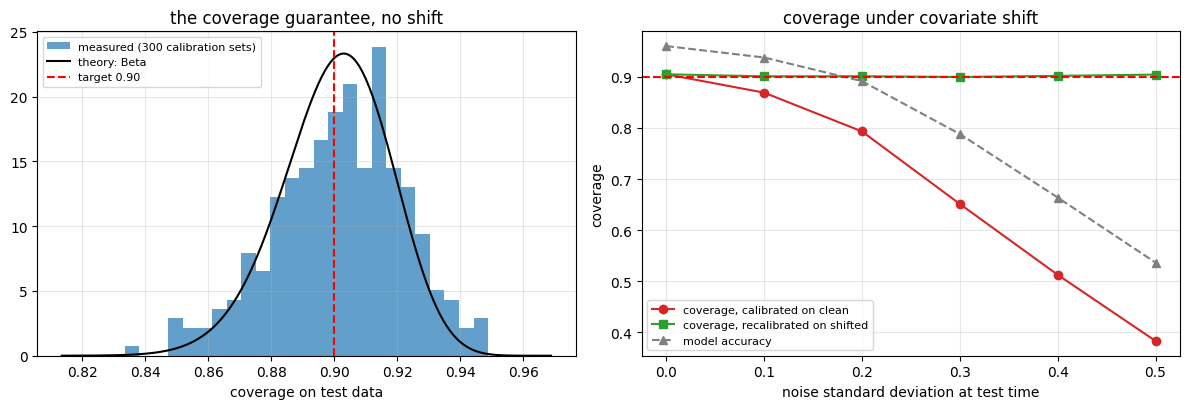

time 8 s


In [6]:
def conformal_qhat(p_cal, y_cal, alpha):
    s = np.sort(1 - p_cal[np.arange(len(y_cal)), y_cal]); n = len(s)
    k = int(np.ceil((n + 1) * (1 - alpha)))
    return s[min(k, n) - 1], k

def conformal_sets(p, qhat): return (1 - p) <= qhat

t0 = time.time()
# a clean 10-class model (clean labels) used here and in sections 8 to 10
idx10_tr, idx10_pool = train_test_split(np.arange(len(Y_ALL)), train_size=500, stratify=Y_ALL, random_state=1)
X10, y10 = X_ALL[idx10_tr], Y_ALL[idx10_tr]
Xpool, ypool = X_ALL[idx10_pool], Y_ALL[idx10_pool]
net10 = fit(X10, y10, seed=0)
ens10 = [net10] + [fit(X10, y10, seed=k) for k in range(1, 5)]
p_pool = softmax_np(logits_of(net10, Xpool))
print(f"clean 10-class model: pool accuracy {(p_pool.argmax(1) == ypool).mean():.3f}, ECE {ece_score(p_pool, ypool):.3f}, pool size {len(ypool)}")

alpha, n_cal, n_rep = 0.1, 300, 300
rs = np.random.default_rng(0)
cover, size = [], []
for _ in range(n_rep):
    perm = rs.permutation(len(ypool)); ic, it = perm[:n_cal], perm[n_cal:]
    qh, k = conformal_qhat(p_pool[ic], ypool[ic], alpha)
    S = conformal_sets(p_pool[it], qh)
    cover.append(S[np.arange(len(it)), ypool[it]].mean()); size.append(S.sum(1).mean())
cover = np.array(cover)
from scipy.stats import beta as beta_dist
th = beta_dist(k, n_cal + 1 - k)
print(f"target 1-alpha = {1 - alpha:.2f}; theoretical mean coverage {k / (n_cal + 1):.3f}, 5-95 % range [{th.ppf(.05):.3f}, {th.ppf(.95):.3f}]")
print(f"measured over {n_rep} calibration sets: mean {cover.mean():.3f}, 5-95 % range [{np.percentile(cover, 5):.3f}, {np.percentile(cover, 95):.3f}], mean set size {np.mean(size):.2f}")

# distribution shift: calibrate on clean data, test on noisier and noisier images
sigmas = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
cov_s, size_s, cov_rc, acc_s = [], [], [], []
for sg in sigmas:
    Xn = corrupt_noise(Xpool, sg, seed=7); pn = softmax_np(logits_of(net10, Xn))
    c, z, cr = [], [], []
    for _ in range(100):
        perm = rs.permutation(len(ypool)); ic, it = perm[:n_cal], perm[n_cal:]
        qh, _ = conformal_qhat(p_pool[ic], ypool[ic], alpha)               # calibrated on CLEAN data
        S = conformal_sets(pn[it], qh); c.append(S[np.arange(len(it)), ypool[it]].mean()); z.append(S.sum(1).mean())
        qh2, _ = conformal_qhat(pn[ic], ypool[ic], alpha)                  # recalibrated on shifted data
        S2 = conformal_sets(pn[it], qh2); cr.append(S2[np.arange(len(it)), ypool[it]].mean())
    cov_s.append(np.mean(c)); size_s.append(np.mean(z)); cov_rc.append(np.mean(cr)); acc_s.append((pn.argmax(1) == ypool).mean())
print(f"{'noise std':>9s} {'accuracy':>9s} {'coverage (clean cal.)':>22s} {'set size':>9s} {'coverage (recalibrated)':>24s}")
for i, sg in enumerate(sigmas):
    print(f"{sg:9.1f} {acc_s[i]:9.3f} {cov_s[i]:22.3f} {size_s[i]:9.2f} {cov_rc[i]:24.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].hist(cover, bins=25, density=True, alpha=0.7, label="measured (300 calibration sets)")
xs = np.linspace(cover.min() - 0.02, cover.max() + 0.02, 300); ax[0].plot(xs, th.pdf(xs), "k", label="theory: Beta")
ax[0].axvline(1 - alpha, c="r", ls="--", label="target 0.90"); ax[0].set_xlabel("coverage on test data"); ax[0].set_title("the coverage guarantee, no shift"); ax[0].legend(fontsize=8)
ax[1].plot(sigmas, cov_s, "o-", c="C3", label="coverage, calibrated on clean"); ax[1].plot(sigmas, cov_rc, "s-", c="C2", label="coverage, recalibrated on shifted")
ax[1].plot(sigmas, acc_s, "^--", c="gray", label="model accuracy"); ax[1].axhline(1 - alpha, c="r", ls="--")
ax[1].set_xlabel("noise standard deviation at test time"); ax[1].set_ylabel("coverage"); ax[1].set_title("coverage under covariate shift"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"time {time.time() - t0:.0f} s")

**Reading.** Over 300 random calibration sets the coverage is 0.901 on average with a 5 to 95 % range of [0.865, 0.933], matching the theory (0.900, [0.871, 0.927]): the guarantee holds and the spread is exactly what the Beta distribution predicts with only 300 calibration points. Note that the mean set size is 0.91, below 1: for a confident model the rule often returns the **empty set** when no class passes the threshold; many implementations always add the top class, which raises coverage slightly. Under shift the guarantee is silently lost. With noise of standard deviation 0.3 accuracy falls to 0.79 and coverage to **0.65** instead of 0.90, and at 0.5 to 0.38, while the sets even get slightly *smaller* (the model stays over-sure). Recalibrating on shifted labelled data restores 0.90 at every level, which is why monitoring with fresh labels matters.

**Where the toy differs from real systems.** Our calibration set has 300 examples and the pool is small, so the Beta band is wide. Real deployments use thousands of calibration examples (tighter band) but face shifts that are gradual and unlabelled, which is why practical systems monitor coverage on a stream of freshly labelled cases. The score $1 - p_y$ is the simplest choice; adaptive scores (APS, RAPS) give sets whose size reflects difficulty better (see the tutorial by Angelopoulos and Bates, 2021).

## 7. Quantile regression and prediction intervals

For regression the analogue of a prediction set is a **prediction interval**. The direct way is **quantile regression** (Koenker and Bassett, 1978): to predict the $\tau$-quantile (for example $\tau = 0.95$: the value below which 95 % of outcomes fall), train with the **pinball loss**

$$\ell_\tau(y, q) = \max\big(\tau\,(y - q),\; (\tau - 1)\,(y - q)\big),$$

which penalises under-prediction with weight $\tau$ and over-prediction with weight $1 - \tau$. A network with three outputs for $\tau \in \{0.05, 0.5, 0.95\}$ gives a median and a 90 % interval whose width can **adapt to $x$**. This is the same idea as the probabilistic forecasts of [module 07 of Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/07-time-series-forecasting/) and of the [Python 1001 time series section](https://python.academy.forwardforecasting.eu/12-time-series-forecasting/).

Quantile networks have no guarantee, so we compare three intervals on the heteroscedastic toy of section 2, now with data everywhere in $[-2, 2]$ (1000 training, 500 calibration, 5000 test points):

* **raw quantile regression**: the interval $[\hat q_{0.05}, \hat q_{0.95}]$;
* **split conformal with a point model**: median $\pm\,\hat q$ where $\hat q$ is the conformal quantile of the absolute residuals $|y - \hat q_{0.5}(x)|$ on the calibration set (guaranteed coverage but a **constant width**);
* **conformalised quantile regression** (CQR, Romano et al., 2019): conformal scores $\max(\hat q_{0.05}(x) - y,\; y - \hat q_{0.95}(x))$, giving the interval $[\hat q_{0.05} - \hat Q, \hat q_{0.95} + \hat Q]$ with a correction $\hat Q$ (guaranteed coverage **and** adaptive width).

The conformal guarantee is **marginal** (averaged over all $x$). We also check coverage **conditional on** $x$ in five bins, and a covariate-shifted test set with $x \in [1, 3]$.

conformal corrections: residual quantile 0.414, CQR correction -0.012
interval                        coverage  mean width   coverage per x-bin (low noise ... high noise)     coverage, x in [1,3]
raw quantile regression            0.900       0.836   0.91 0.89 0.91 0.93 0.85                    0.483
split conformal (median ± q)       0.869       0.827   1.00 0.98 0.90 0.80 0.68                    0.435
CQR                                0.886       0.813   0.88 0.87 0.90 0.93 0.85                    0.478


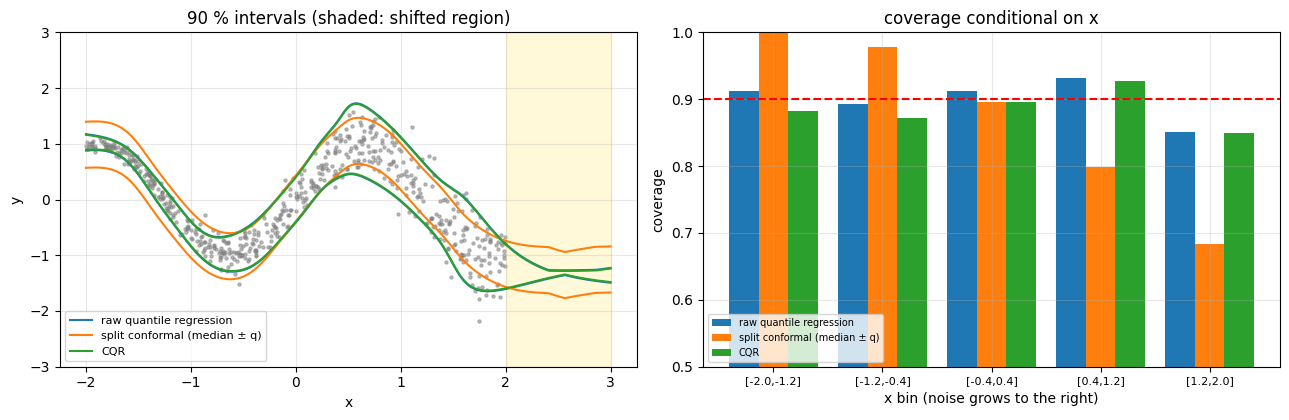

time 21 s


In [7]:
t0 = time.time()
rg = np.random.default_rng(1)
def make_reg(n, lo, hi):
    x = rg.uniform(lo, hi, n); return x, f_true(x) + s_true(x) * rg.standard_normal(n)
xa, ya = make_reg(1000, -2, 2); xc, yc = make_reg(500, -2, 2); xe, ye = make_reg(5000, -2, 2); xs_, ys_ = make_reg(5000, 1, 3)
TAUS = torch.tensor([0.05, 0.5, 0.95])

def fit_quant(seed, steps=1200):
    torch.manual_seed(seed)
    net = nn.Sequential(nn.Linear(1, 64), nn.Tanh(), nn.Linear(64, 64), nn.Tanh(), nn.Linear(64, 3))
    opt = torch.optim.Adam(net.parameters(), lr=5e-3)
    X = torch.tensor(xa, dtype=torch.float32)[:, None]; Y = torch.tensor(ya, dtype=torch.float32)[:, None]
    for _ in range(steps):
        e = Y - net(X)
        loss = torch.maximum(TAUS * e, (TAUS - 1) * e).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    return net

qnet = fit_quant(0)
def qpred(x):
    with torch.no_grad():
        q = qnet(torch.tensor(x, dtype=torch.float32)[:, None]).numpy()
    return np.sort(q, axis=1)                  # sort to avoid crossing quantiles
def conf_quantile(scores, alpha=0.1):
    n = len(scores); k = int(np.ceil((n + 1) * (1 - alpha))); return np.sort(scores)[min(k, n) - 1]

qc = qpred(xc)
Q_res = conf_quantile(np.abs(yc - qc[:, 1]))
Q_cqr = conf_quantile(np.maximum(qc[:, 0] - yc, yc - qc[:, 2]))
def intervals(x):
    q = qpred(x)
    return {"raw quantile regression": (q[:, 0], q[:, 2]),
            "split conformal (median ± q)": (q[:, 1] - Q_res, q[:, 1] + Q_res),
            "CQR": (q[:, 0] - Q_cqr, q[:, 2] + Q_cqr)}
bins = np.linspace(-2, 2, 6)
print(f"conformal corrections: residual quantile {Q_res:.3f}, CQR correction {Q_cqr:+.3f}")
print(f"{'interval':30s} {'coverage':>9s} {'mean width':>11s}   coverage per x-bin (low noise ... high noise)   {'coverage, x in [1,3]':>22s}")
for name, (lo, hi) in intervals(xe).items():
    inside = (ye >= lo) & (ye <= hi)
    per_bin = [inside[(xe >= bins[b]) & (xe < bins[b + 1] + 1e-9)].mean() for b in range(5)]
    lo2, hi2 = intervals(xs_)[name]; cov_shift = ((ys_ >= lo2) & (ys_ <= hi2)).mean()
    print(f"{name:30s} {inside.mean():9.3f} {(hi - lo).mean():11.3f}   " + " ".join(f"{c:.2f}" for c in per_bin) + f"   {cov_shift:22.3f}")

xg2 = np.linspace(-2, 3, 300); iv = intervals(xg2)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
ax[0].scatter(xe[:600], ye[:600], s=5, c="gray", alpha=0.5)
for k, (name, (lo, hi)) in enumerate(iv.items()):
    ax[0].plot(xg2, lo, c=f"C{k}", label=name); ax[0].plot(xg2, hi, c=f"C{k}")
ax[0].axvspan(2, 3, color="gold", alpha=0.15); ax[0].set_ylim(-3, 3); ax[0].set_xlabel("x"); ax[0].set_ylabel("y")
ax[0].set_title("90 % intervals (shaded: shifted region)"); ax[0].legend(fontsize=8, loc="lower left")
w = 0.27
for k, (name, (lo, hi)) in enumerate(intervals(xe).items()):
    inside = (ye >= lo) & (ye <= hi)
    ax[1].bar(np.arange(5) + (k - 1) * w, [inside[(xe >= bins[b]) & (xe < bins[b + 1] + 1e-9)].mean() for b in range(5)], width=w, color=f"C{k}", label=name)
ax[1].axhline(0.9, c="r", ls="--"); ax[1].set_xticks(range(5)); ax[1].set_xticklabels([f"[{bins[b]:.1f},{bins[b+1]:.1f}]" for b in range(5)], fontsize=8)
ax[1].set_ylim(0.5, 1.0); ax[1].set_xlabel("x bin (noise grows to the right)"); ax[1].set_ylabel("coverage"); ax[1].set_title("coverage conditional on x"); ax[1].legend(fontsize=7, loc="lower left")
plt.tight_layout(); plt.show()
print(f"time {time.time() - t0:.0f} s")

**Reading.** All three intervals reach roughly the nominal coverage on average (raw quantile regression 0.900, CQR 0.886, split conformal 0.869; with 500 calibration points one calibration set can legitimately land a couple of points off, and 0.869 is at the edge of that spread), and they have about the same mean width (0.81 to 0.84). **Conditionally on $x$ they are very different**: split conformal with a constant width covers 100 % in the quietest bin and only 68 % in the noisiest, while the quantile-based intervals adapt their width and stay within 0.85 to 0.93 in every bin. CQR's correction was tiny here (-0.012) because the raw quantile network was already well calibrated; its value is the guarantee, not a change in this particular fit. In the shifted region $x \in [1, 3]$, where there is no training data and the noise keeps growing, **every method covers only 0.44 to 0.48**: no interval fixes extrapolation, conformal included.

**Where the toy differs from real systems.** One input dimension makes conditional coverage easy to inspect; in high dimensions you cannot bin by $x$, and exact conditional coverage is impossible without assumptions (a known result), so practice relies on adaptive methods like CQR plus monitoring on important subgroups.

## 8. Distribution shift: corrupted images

So far "shift" has meant added noise. Hendrycks and Dietterich (2019) made it a benchmark: take a test set and apply realistic **corruptions** (noise, blur, weather, digital artefacts) at increasing **severity**, and measure how accuracy and calibration degrade. We apply three corruptions to the 8 by 8 digits, each at six severities:

* **Gaussian noise** with standard deviation 0 to 0.5 (a noisy sensor);
* **Gaussian blur** with width 0 to 2.5 pixels (an out-of-focus camera; on an 8 by 8 image a width of 1.5 already blurs neighbouring strokes together);
* **rotation** by 0 to 60 degrees (a tilted camera).

We compare the single network with the 5-member ensemble of section 4 on **accuracy** and **ECE**. Ovadia et al. (2019) report that calibration degrades steadily with shift and that ensembles degrade the most gracefully; we check that on this toy.

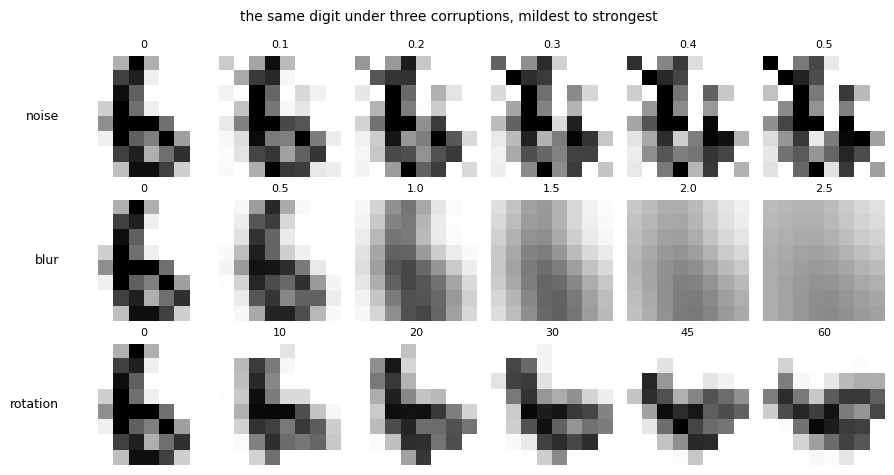

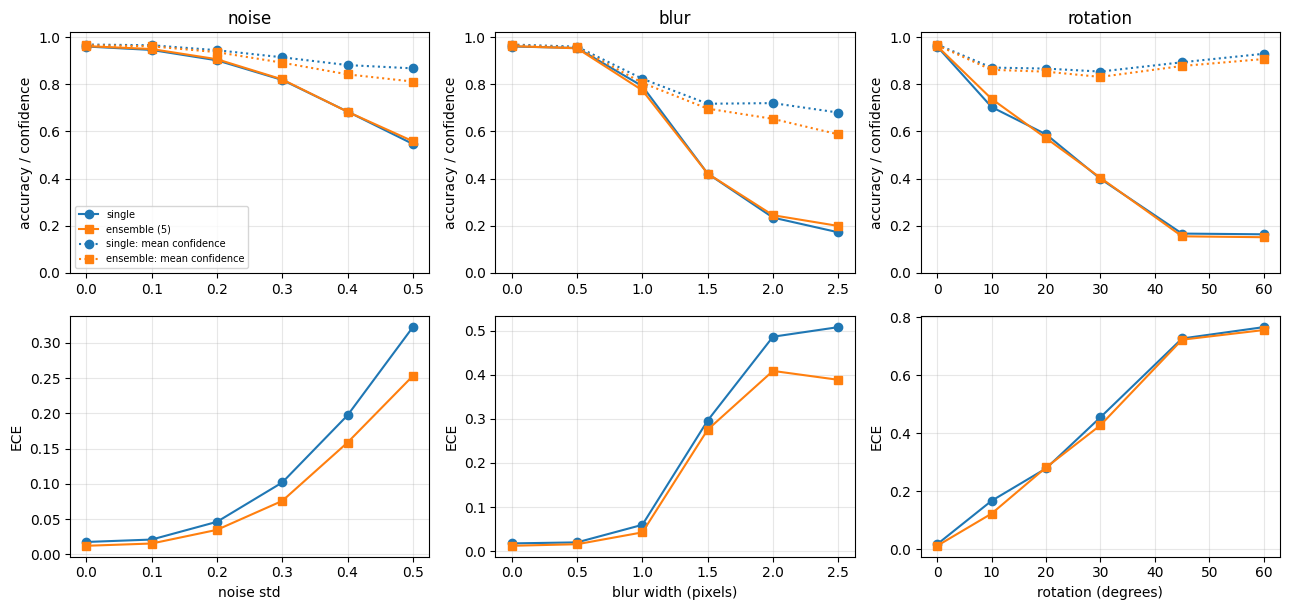

corruption @ level       acc single ECE single  acc ens  ECE ens
noise @ 0                     0.960      0.018    0.961    0.012
noise @ 0.3                   0.818      0.102    0.820    0.076
noise @ 0.5                   0.547      0.322    0.558    0.253
blur @ 0                      0.960      0.018    0.961    0.012
blur @ 1.5                    0.421      0.296    0.421    0.275
blur @ 2.5                    0.172      0.508    0.199    0.388
rotation @ 0                  0.960      0.018    0.961    0.012
rotation @ 30                 0.399      0.455    0.403    0.428
rotation @ 60                 0.163      0.766    0.151    0.756
time 6 s


In [8]:
def corrupt_blur(X, sigma):
    if sigma == 0: return X
    return np.stack([ndimage.gaussian_filter(x.reshape(8, 8), sigma).reshape(-1) for x in X]).astype(np.float32)
def corrupt_rot(X, deg):
    if deg == 0: return X
    return np.stack([np.clip(ndimage.rotate(x.reshape(8, 8), deg, reshape=False, order=1, mode="constant"), 0, 1).reshape(-1) for x in X]).astype(np.float32)

CORR = {"noise": (lambda X, s: corrupt_noise(X, s, seed=3), [0, 0.1, 0.2, 0.3, 0.4, 0.5], "noise std"),
        "blur": (corrupt_blur, [0, 0.5, 1.0, 1.5, 2.0, 2.5], "blur width (pixels)"),
        "rotation": (corrupt_rot, [0, 10, 20, 30, 45, 60], "rotation (degrees)")}

# a few examples
fig, ax = plt.subplots(3, 6, figsize=(9, 4.8))
for r, (name, (fn, levels, lab)) in enumerate(CORR.items()):
    for c, lv in enumerate(levels):
        ax[r, c].imshow(fn(Xpool[:1], lv).reshape(8, 8), cmap="gray_r", vmin=0, vmax=1); ax[r, c].axis("off"); ax[r, c].set_title(f"{lv}", fontsize=8)
    ax[r, 0].text(-0.2, 0.5, name, transform=ax[r, 0].transAxes, ha="right", va="center", fontsize=9)
plt.suptitle("the same digit under three corruptions, mildest to strongest", fontsize=10); plt.tight_layout(); plt.show()

t0 = time.time()
def ens_probs(models, X): return np.mean([softmax_np(logits_of(m, X)) for m in models], 0)
shift_res = {}
for name, (fn, levels, lab) in CORR.items():
    rows = []
    for lv in levels:
        Xc = fn(Xpool, lv)
        p1, pe = softmax_np(logits_of(net10, Xc)), ens_probs(ens10, Xc)
        rows.append([(p1.argmax(1) == ypool).mean(), ece_score(p1, ypool), p1.max(1).mean(), (pe.argmax(1) == ypool).mean(), ece_score(pe, ypool), pe.max(1).mean()])
    shift_res[name] = np.array(rows)
fig, ax = plt.subplots(2, 3, figsize=(13, 6.2))
for j, (name, (fn, levels, lab)) in enumerate(CORR.items()):
    R = shift_res[name]
    ax[0, j].plot(levels, R[:, 0], "o-", label="single"); ax[0, j].plot(levels, R[:, 3], "s-", label="ensemble (5)"); ax[0, j].plot(levels, R[:, 2], "o:", c="C0", label="single: mean confidence"); ax[0, j].plot(levels, R[:, 5], "s:", c="C1", label="ensemble: mean confidence")
    ax[0, j].set_title(name); ax[0, j].set_ylabel("accuracy / confidence"); ax[0, j].set_ylim(0, 1.02)
    ax[1, j].plot(levels, R[:, 1], "o-", label="single"); ax[1, j].plot(levels, R[:, 4], "s-", label="ensemble (5)"); ax[1, j].set_xlabel(lab); ax[1, j].set_ylabel("ECE")
ax[0, 0].legend(fontsize=7); plt.tight_layout(); plt.show()
print(f"{'corruption @ level':24s} {'acc single':>10s} {'ECE single':>10s} {'acc ens':>8s} {'ECE ens':>8s}")
for name, (fn, levels, lab) in CORR.items():
    for i in [0, 3, 5]:
        R = shift_res[name][i]
        print(f"{name + ' @ ' + str(levels[i]):24s} {R[0]:10.3f} {R[1]:10.3f} {R[3]:8.3f} {R[4]:8.3f}")
print(f"time {time.time() - t0:.0f} s")

**Reading.** All three corruptions destroy accuracy as severity grows, and the confidence does not follow it down. Noise 0.3 lowers accuracy from 0.96 to 0.82 and raises ECE from 0.018 to 0.10; rotation by 30 degrees brings accuracy to 0.40 with ECE 0.46 (the model is wrong more than half the time but sounds sure); blur 1.5 gives 0.42 and ECE 0.30. The ensemble is **better calibrated than the single network in most cases** (noise 0.5: ECE 0.25 against 0.32; blur 2.5: 0.39 against 0.51) with the same accuracy, but for rotation it gives almost no advantage (0.43 against 0.46 at 30 degrees). Agreeing with Ovadia et al. (2019), an ensemble helps but does not rescue calibration under shift. These are single runs of one trained model, so small gaps (for example in accuracy) are not meaningful.

**Where the toy differs from real systems.** Corruptions applied to a 64-pixel image are crude cousins of the 15 corruption types and 5 severities of the real benchmark (Hendrycks and Dietterich, 2019), and real shifts are often **not** a known corruption at all but a new camera, season or population. That is why monitoring in production (section 11) matters more than any single robustness trick.

## 9. Adversarial examples and adversarial training

A different kind of shift is *deliberate*. Szegedy et al. (2014) found that tiny, carefully chosen perturbations of an input can flip a network's prediction. Goodfellow et al. (2015) explained why with a one-line attack. Let $\mathcal L(x, y)$ be the loss of the model on input $x$ with true label $y$. The **fast gradient sign method** (FGSM) moves every pixel by $\varepsilon$ (epsilon, the perturbation budget) in the direction that increases the loss:

$$x' = \mathrm{clip}_{[0,1]}\Big(x + \varepsilon \cdot \mathrm{sign}\big(\nabla_x \mathcal L(x, y)\big)\Big).$$

**Projected gradient descent** (PGD, Madry et al., 2018) repeats this in $T$ small steps of size $\eta$ (eta) from a random start inside the allowed region, projecting back after every step onto the set of images within $\varepsilon$ of the original in every pixel (the $\ell_\infty$ ball, where $\ell_\infty$ is the largest per-pixel change):

$$x^{t+1} = \Pi_{\|x'-x\|_\infty \le \varepsilon}\Big(x^t + \eta \cdot \mathrm{sign}\big(\nabla_x \mathcal L(x^t, y)\big)\Big).$$

PGD is a stronger attack because it uses many gradient steps instead of one. **Adversarial training** (Madry et al., 2018) defends by training on the attacker's output: at every step, generate PGD examples against the current model and minimise the loss on **them**. This costs one extra forward-backward pass per attack step. We measure: accuracy against $\varepsilon$ for FGSM and PGD on the standard network, then adversarial training with $\varepsilon = 0.1$ (about 1.6 grey levels of 16, on pixels scaled to $[0,1]$), its accuracy cost and its **time** cost.

training time: standard 1.1 s, adversarial 7.0 s  (x6.2)
  eps  standard FGSM  standard PGD  adv-trained FGSM  adv-trained PGD
 0.00          0.960         0.960             0.972            0.972
 0.02          0.906         0.905             0.951            0.951
 0.05          0.753         0.748             0.917            0.914
 0.10          0.332         0.300             0.773            0.752
 0.15          0.059         0.037             0.548            0.497
 0.20          0.007         0.000             0.289            0.180
 0.30          0.002         0.000             0.002            0.000


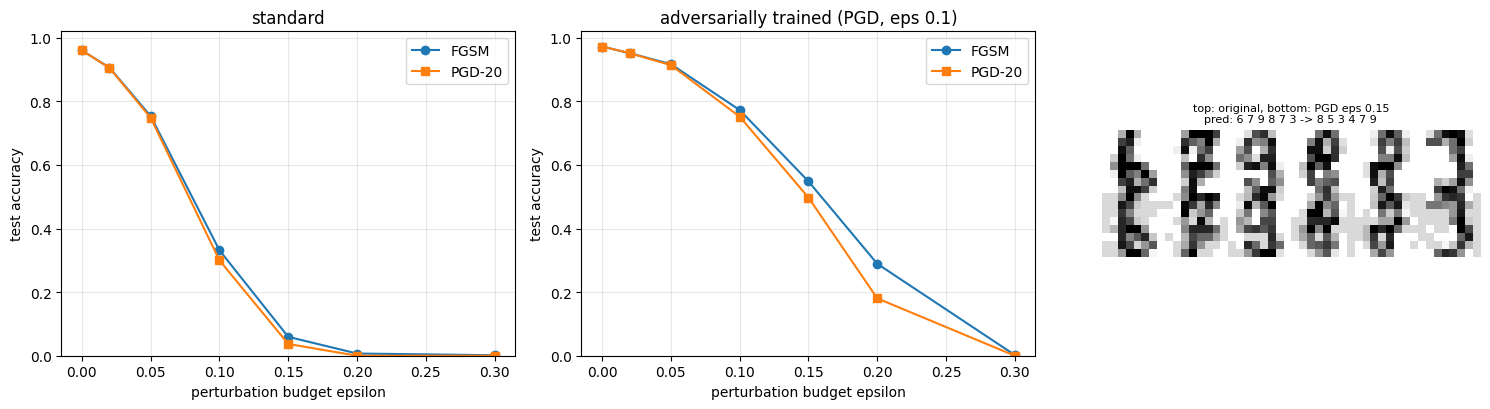

time 16 s


In [9]:
def fgsm(model, X, y, eps):
    x = torch.as_tensor(X, dtype=torch.float32).clone().requires_grad_(True)
    loss = F.cross_entropy(model(x), torch.as_tensor(y))
    g, = torch.autograd.grad(loss, x)
    return (x + eps * g.sign()).clamp(0, 1).detach()

def pgd(model, X, y, eps, steps=20, seed=0):
    X0 = torch.as_tensor(X, dtype=torch.float32); yt_ = torch.as_tensor(y); alpha = 2.5 * eps / steps
    g = torch.Generator().manual_seed(seed)
    x = (X0 + (torch.rand(X0.shape, generator=g) * 2 - 1) * eps).clamp(0, 1)
    for _ in range(steps):
        x.requires_grad_(True)
        loss = F.cross_entropy(model(x), yt_)
        grad, = torch.autograd.grad(loss, x)
        x = x.detach() + alpha * grad.sign()
        x = torch.min(torch.max(x, X0 - eps), X0 + eps).clamp(0, 1)          # project onto the eps-ball and valid pixels
    return x.detach()

def adv_fit(X, y, seed, eps=0.1, steps=5, epochs=100, lr=3e-3, d_out=10):
    torch.manual_seed(seed)
    m = make_mlp(d_out); opt = torch.optim.Adam(m.parameters(), lr=lr); yt_ = torch.as_tensor(y)
    for e in range(epochs):
        m.eval(); xa_ = pgd(m, X, y, eps, steps, seed=e); m.train()
        loss = F.cross_entropy(m(xa_), yt_)
        opt.zero_grad(); loss.backward(); opt.step()
    return m.eval()

def acc_on(model, X, y):
    with torch.no_grad(): return float((model(torch.as_tensor(X, dtype=torch.float32)).argmax(1).numpy() == y).mean())

t0 = time.time()
tt = time.time(); _ = fit(X10, y10, seed=0); t_std = time.time() - tt
tt = time.time(); net_adv = adv_fit(X10, y10, seed=0); t_adv = time.time() - tt
eps_list = [0.0, 0.02, 0.05, 0.1, 0.15, 0.2, 0.3]
Xt_, yt10 = Xpool, ypool
curves = {}
for name, mdl in [("standard", net10), ("adversarially trained (PGD, eps 0.1)", net_adv)]:
    curves[name] = {"FGSM": [acc_on(mdl, fgsm(mdl, Xt_, yt10, e).numpy(), yt10) for e in eps_list],
                    "PGD": [acc_on(mdl, pgd(mdl, Xt_, yt10, e, 20).numpy(), yt10) for e in eps_list]}
print(f"training time: standard {t_std:.1f} s, adversarial {t_adv:.1f} s  (x{t_adv / t_std:.1f})")
print(f"{'eps':>5s} {'standard FGSM':>14s} {'standard PGD':>13s} {'adv-trained FGSM':>17s} {'adv-trained PGD':>16s}")
for i, e in enumerate(eps_list):
    c1, c2 = curves["standard"], curves["adversarially trained (PGD, eps 0.1)"]
    print(f"{e:5.2f} {c1['FGSM'][i]:14.3f} {c1['PGD'][i]:13.3f} {c2['FGSM'][i]:17.3f} {c2['PGD'][i]:16.3f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1.2, 1.2, 1]})
for k, (name, c) in enumerate(curves.items()):
    ax[k].plot(eps_list, c["FGSM"], "o-", label="FGSM"); ax[k].plot(eps_list, c["PGD"], "s-", label="PGD-20")
    ax[k].set_title(name); ax[k].set_xlabel("perturbation budget epsilon"); ax[k].set_ylabel("test accuracy"); ax[k].set_ylim(0, 1.02); ax[k].legend()
ex = np.arange(6)
xadv = pgd(net10, Xt_[ex], yt10[ex], 0.15, 20).numpy()
with torch.no_grad(): pa = net10(torch.as_tensor(xadv)).argmax(1).numpy(); p0 = net10(torch.as_tensor(Xt_[ex])).argmax(1).numpy()
ax[2].axis("off"); sub = ax[2].inset_axes([0, 0, 1, 1]); sub.axis("off")
strip = np.concatenate([np.concatenate([Xt_[i].reshape(8, 8) for i in ex], 1), np.concatenate([xadv[j].reshape(8, 8) for j in range(6)], 1)], 0)
sub.imshow(strip, cmap="gray_r", vmin=0, vmax=1); sub.set_title("top: original, bottom: PGD eps 0.15\npred: " + " ".join(map(str, p0)) + " -> " + " ".join(map(str, pa)), fontsize=8)
plt.tight_layout(); plt.show()
print(f"time {time.time() - t0:.0f} s")

**Reading.** The standard network is fragile: with a budget of only 0.05 per pixel accuracy falls from 0.96 to 0.75, at 0.1 to 0.33 (FGSM) and 0.30 (PGD), and PGD at 0.2 drives it to exactly 0. PGD is stronger than FGSM, the more so as epsilon grows. **Adversarial training** (PGD with 5 steps at epsilon 0.1) keeps 0.75 accuracy against PGD-20 at epsilon 0.1 (against 0.30) and 0.50 at 0.15, and **it did not cost clean accuracy here** (0.972 against 0.960; on this tiny dataset the extra perturbed data probably acts as regularisation, from one seed, so do not generalise). It does not help beyond its training budget: at epsilon 0.3 both networks are at 0. The **cost** is time: 7.0 s against 1.1 s to train, 6.2 times more, which matches the 5 attack steps plus the update.

**Where the toy differs from real systems.** An 8 by 8 digit with a small multilayer network is easy to attack and cheap to train adversarially. On ImageNet-sized images the same perturbation budget is invisible to the eye, adversarial training costs 5 to 10 times more compute, and the accuracy price is larger. Also, PGD with one random start only gives an *upper bound* on robust accuracy: stronger attack suites (for instance AutoAttack) can lower it further, and a defence that merely hides gradients can look robust to FGSM while failing against better attacks (**gradient masking**).

## 10. Data augmentation as a robustness tool

The cheapest robustness tool is the one from module 03 of Neural Networks 1001: **augment the training data** with the variations you expect at test time. Here we train the same network on the 500 training digits plus 6 randomly corrupted copies of each (noise with standard deviation drawn uniformly from 0 to 0.4, and a rotation drawn uniformly between -30 and +30 degrees). Then we test on:

* noise 0.3 and rotation 30 degrees: corruptions **seen** in augmentation;
* **blur 1.5**: a corruption the augmentation **never used**, to see whether robustness generalises;
* **FGSM and PGD at epsilon 0.1**: adversarial attacks, against the standard, the augmented and the adversarially trained network of section 9.

The question is whether robustness to one family transfers to another.

augmented training set: 3500 images, trained in 7 s


model                                      clean    noise 0.3 (seen)  rotation 30 (seen)   blur 1.5 (unseen)            FGSM 0.1          PGD-20 0.1


standard                                   0.960               0.818               0.399               0.421               0.332               0.300


augmented (noise+rotation)                 0.950               0.758               0.839               0.372               0.290               0.242


adversarial (PGD 0.1)                      0.972               0.882               0.473               0.628               0.773               0.752


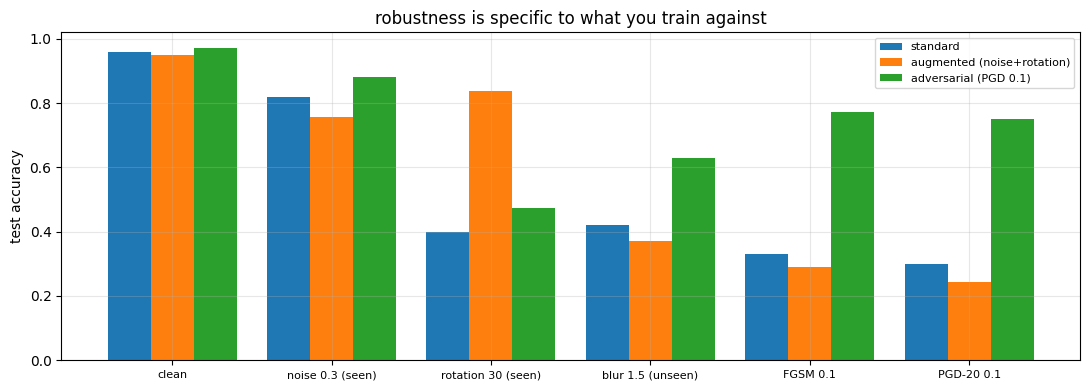

In [10]:
t0 = time.time()
ra = np.random.default_rng(5)
def augment(X, copies=6):
    out = [X]
    for _ in range(copies):
        Xc = np.stack([corrupt_noise(x[None], ra.uniform(0, 0.4), seed=int(ra.integers(1e9)))[0] for x in X])
        Xc = np.stack([corrupt_rot(x[None], float(ra.uniform(-30, 30)))[0] for x in Xc])
        out.append(Xc)
    return np.concatenate(out).astype(np.float32)
X_aug = augment(X10); y_aug = np.tile(y10, 7)
net_aug = fit(X_aug, y_aug, seed=0)
print(f"augmented training set: {len(X_aug)} images, trained in {time.time() - t0:.0f} s")

tests = {"clean": Xpool, "noise 0.3 (seen)": corrupt_noise(Xpool, 0.3, 3), "rotation 30 (seen)": corrupt_rot(Xpool, 30), "blur 1.5 (unseen)": corrupt_blur(Xpool, 1.5)}
models = {"standard": net10, "augmented (noise+rotation)": net_aug, "adversarial (PGD 0.1)": net_adv}
print(f"{'model':28s} " + " ".join(f"{k:>19s}" for k in list(tests) + ["FGSM 0.1", "PGD-20 0.1"]))
rob = {}
for name, mdl in models.items():
    accs = [acc_on(mdl, X, ypool) for X in tests.values()]
    accs += [acc_on(mdl, fgsm(mdl, Xpool, ypool, 0.1).numpy(), ypool), acc_on(mdl, pgd(mdl, Xpool, ypool, 0.1, 20).numpy(), ypool)]
    rob[name] = accs
    print(f"{name:28s} " + " ".join(f"{a:19.3f}" for a in accs))

fig, ax = plt.subplots(figsize=(11, 4))
labels = list(tests) + ["FGSM 0.1", "PGD-20 0.1"]; wd = 0.27
for k, (name, accs) in enumerate(rob.items()):
    ax.bar(np.arange(len(labels)) + (k - 1) * wd, accs, width=wd, label=name)
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, fontsize=8); ax.set_ylabel("test accuracy"); ax.set_ylim(0, 1.02); ax.legend(fontsize=8, loc="upper right")
ax.set_title("robustness is specific to what you train against"); plt.tight_layout(); plt.show()

**Reading.** Robustness is **specific to what you train against**. Augmenting with noise and rotation lifted rotation 30 from 0.40 to 0.84, a large gain, but it did **not** help the noise level 0.3 it also saw (0.76 against 0.82 for the standard network: the model was trained on a broad mix of noise and rotation, which cost some accuracy on each) and it hurt the unseen blur (0.37 against 0.42) and the adversarial attacks (0.24 under PGD against 0.30). The adversarially trained network, on the other hand, was also more robust to noise 0.3 (0.88) and to blur (0.63), corruptions it never saw, besides its target attack; but it hardly helped with rotation (0.47). So no single method covers all shifts; choose augmentations from the shifts you expect, test on shifts you did not train on, and note that all of this is from one seed per model.

## 11. A checklist for production

A confidence is a product feature with failure modes, not a free by-product of the softmax. Before you put one in front of a user or a downstream system:

1. **State what the number means.** "Probability the label is right", "interval containing 90 % of outcomes", or "ranking score"? Only the first two can be audited.
2. **Hold out data for calibration and never reuse it** for early stopping or model choice. Fit $T$ (or the conformal quantile) there, report ECE and NLL on a third, untouched set.
3. **Measure calibration where the model will be used**, per subgroup and per slice (time period, device, region). Overall calibration can hide a subgroup that is badly off.
4. **Choose the tool for the need.** Better probabilities: temperature scaling first (free), then ensembles. Guaranteed coverage: conformal. Adaptive intervals for regression: CQR. Detection of novel inputs: ensembles' disagreement, MSP as the baseline to beat.
5. **Plan for shift.** Log the confidence, monitor its distribution and the coverage on a stream of labelled samples, and set an alarm when they move. Re-calibrate (section 6 showed it restores coverage) when labels arrive.
6. **Define the abstain path.** A reject option is only useful if a person, a slower model or a safe default is waiting on the other side, and the cost of abstaining is accounted for.
7. **Decide the threat model.** If nobody adversarial can touch the input, corruptions and augmentation are the relevant tests; if they can, add attack evaluation (PGD at least, stronger suites better) and accept the accuracy and compute cost of adversarial training.
8. **Budget the cost.** An ensemble of $M$ costs $M$ times the compute; MC dropout $S$ times at prediction; conformal and temperature scaling are almost free. Pick the cheapest method that meets the measured requirement.
9. **Re-measure after every retraining.** Calibration is a property of one trained model, not of the architecture.
10. **Communicate honestly.** Show sets or intervals instead of a falsely precise single number, and write down the conditions (data, shift range, coverage level) under which the guarantee was measured.

## Key takeaways

* A prediction needs a confidence that **means something**. Accuracy and calibration are different properties; calibrated confidences enable thresholds, hand-offs and risk pricing.
* **Aleatoric** uncertainty (noise in the data) does not shrink with more data and a network can learn it; **epistemic** uncertainty (no data here) shows up as disagreement between plausible models, large in gaps and outside the training range (section 2).
* Networks trained to memorise are **overconfident**; **temperature scaling** with one fitted number reduced ECE without changing a single prediction (section 3). It does not know *where* the model is unsure.
* **Ensembles, MC dropout and Laplace** give input-dependent uncertainty. In our toy the ordering was not uniform across criteria, and differences between methods were often inside the seed noise (section 4); ensembles cost $M$ times as much.
* **Selective prediction** turns confidence into accuracy-for-coverage trades (section 5).
* **Conformal prediction** gave **measured** 90 % coverage for any model, with a Beta-distributed spread across calibration sets, and lost it under shift until we recalibrated (section 6). **CQR** kept the guarantee and adapted its width to the noise (section 7).
* **Distribution shift** degraded accuracy and calibration together; confidence stayed too high (section 8).
* **Adversarial examples** collapse a standard network at tiny budgets; **PGD** is stronger than FGSM; adversarial training buys robustness at a measured cost in time and clean accuracy (section 9).
* **Augmentation** is robust only to what you augment against (section 10). Monitor, recalibrate, and write the checklist of section 11 into your project.

## Exercises

1. In section 2, give the training data a second gap at $x \in [1.2, 1.5]$. Does the epistemic standard deviation rise there, and how does it change with $M = 2, 5, 12$?
2. In section 3, train on clean labels instead of 25 % wrong labels. How do the fitted $T$, the ECE before and after, and the reliability diagram change? Then fit $T$ on the *noisy test set* of section 8 (noise 0.3) and check it on rotated images.
3. In section 4, add a **temperature-scaled ensemble** and a **single network with weight decay**. Does either match the ensemble on the OOD AUROC? Use 5 seeds instead of 3.
4. In section 5, rank by the mutual information (for the ensemble) instead of the maximum probability. Which gives the better accuracy at 80 % coverage?
5. In section 6, change $\alpha$ to 0.05 and the calibration size to 50. Compare the measured coverage spread with the Beta band. Then implement the **adaptive prediction sets** score (sum of the sorted probabilities up to the true class) and compare set sizes.
6. In section 7, quantile-regress with 5 000 training points but only 100 calibration points. What happens to the width of the CQR correction and to coverage in each bin?
7. In section 8, add a **brightness** corruption (add a constant to all pixels) and a **translation** by 1 pixel. Which hurts most, and does the ensemble still help?
8. In section 9, adversarially train with $\varepsilon = 0.2$ and compare the clean accuracy, the PGD curve and the training time. Then evaluate with 100 PGD steps to check that robust accuracy does not drop (a sanity check against gradient masking).
9. In section 10, add blur to the augmentation and re-test on rotation 45 (unseen). Is the augmented network with the widest range always best, and what does it cost in clean accuracy?
10. Take any classifier you have used before, hold out 20 % of its data for conformal calibration, and report the average set size and the measured coverage with a 5 to 95 % range.

## References

* Alpaydin, E. and Kaynak, C. (1998). Optical Recognition of Handwritten Digits (UCI Machine Learning Repository, CC BY 4.0). https://doi.org/10.24432/C50P49
* Guo, C., Pleiss, G., Sun, Y. and Weinberger, K. Q. (2017). On calibration of modern neural networks. ICML. arXiv:1706.04599: https://arxiv.org/abs/1706.04599
* Lakshminarayanan, B., Pritzel, A. and Blundell, C. (2017). Simple and scalable predictive uncertainty estimation using deep ensembles. NeurIPS. arXiv:1612.01474: https://arxiv.org/abs/1612.01474
* Gal, Y. and Ghahramani, Z. (2016). Dropout as a Bayesian approximation: representing model uncertainty in deep learning. ICML. arXiv:1506.02142: https://arxiv.org/abs/1506.02142
* Kendall, A. and Gal, Y. (2017). What uncertainties do we need in Bayesian deep learning for computer vision? NeurIPS. arXiv:1703.04977: https://arxiv.org/abs/1703.04977
* Daxberger, E. et al. (2021). Laplace Redux: effortless Bayesian deep learning. NeurIPS. arXiv:2106.14806: https://arxiv.org/abs/2106.14806
* Hendrycks, D. and Gimpel, K. (2017). A baseline for detecting misclassified and out-of-distribution examples in neural networks. ICLR. arXiv:1610.02136: https://arxiv.org/abs/1610.02136
* Geifman, Y. and El-Yaniv, R. (2017). Selective classification for deep neural networks. NeurIPS. arXiv:1705.08500: https://arxiv.org/abs/1705.08500
* Angelopoulos, A. N. and Bates, S. (2021). A gentle introduction to conformal prediction and distribution-free uncertainty quantification. arXiv:2107.07511: https://arxiv.org/abs/2107.07511
* Koenker, R. and Bassett, G. (1978). Regression quantiles. *Econometrica* 46(1), 33-50: https://doi.org/10.2307/1913643
* Romano, Y., Patterson, E. and Candes, E. (2019). Conformalized quantile regression. NeurIPS. arXiv:1905.03222: https://arxiv.org/abs/1905.03222
* Hendrycks, D. and Dietterich, T. (2019). Benchmarking neural network robustness to common corruptions and perturbations. ICLR. arXiv:1903.12261: https://arxiv.org/abs/1903.12261
* Ovadia, Y. et al. (2019). Can you trust your model's uncertainty? Evaluating predictive uncertainty under dataset shift. NeurIPS. arXiv:1906.02530: https://arxiv.org/abs/1906.02530
* Szegedy, C. et al. (2014). Intriguing properties of neural networks. ICLR. arXiv:1312.6199: https://arxiv.org/abs/1312.6199
* Goodfellow, I. J., Shlens, J. and Szegedy, C. (2015). Explaining and harnessing adversarial examples. ICLR. arXiv:1412.6572: https://arxiv.org/abs/1412.6572
* Madry, A., Makelov, A., Schmidt, L., Tsipras, D. and Vladu, A. (2018). Towards deep learning models resistant to adversarial attacks. ICLR. arXiv:1706.06083: https://arxiv.org/abs/1706.06083

In [11]:
print(f"total notebook run time: {time.time() - T_START:.0f} s")

total notebook run time: 219 s
